# Healthcare Analytics for Doctor Visits
### Major Project — DIY Project Batch 2026-2027

**Objective:** Analyze patient-level survey data to understand which personal, financial, and health-related factors are associated with the number of doctor visits -- and surface patterns that could support better healthcare planning.

**Dataset:** `healthcare_doctor_visits.csv` — 5,190 patient records, 13 columns, covering demographics, income, illness/health indicators, healthcare support programs, and chronic conditions.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10
pd.set_option('display.max_columns', None)

PALETTE = {'no': '#2E83C3', 'yes': '#2E946B'}

## 2. Load the Dataset

In [2]:
df = pd.read_csv('healthcare_doctor_visits.csv')
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Shape: 5190 rows, 13 columns


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   str    
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   str    
 9   freepoor    5190 non-null   str    
 10  freerepat   5190 non-null   str    
 11  nchronic    5190 non-null   str    
 12  lchronic    5190 non-null   str    
dtypes: float64(2), int64(5), str(6)
memory usage: 527.2 KB


## 3. Dataset Overview

Each row is one surveyed person. `visits` (the number of doctor visits) is the main outcome of interest. The dataset mixes numeric health indicators (illness count, reduced-activity days, a general-health score), financial information (income), and several yes/no healthcare-support and chronic-condition flags.

In [4]:
print("Categorical fields:")
for col in ['gender', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']:
    print(f"  {col}: {sorted(df[col].unique())}")

print("\nNumeric field ranges:")
print(df[['age', 'income', 'illness', 'reduced', 'health', 'visits']].describe().T)

Categorical fields:
  gender: ['female', 'male']
  private: ['no', 'yes']
  freepoor: ['no', 'yes']
  freerepat: ['no', 'yes']
  nchronic: ['no', 'yes']
  lchronic: ['no', 'yes']

Numeric field ranges:
          count      mean       std   min   25%   50%   75%    max
age      5190.0  0.406385  0.204782  0.19  0.22  0.32  0.62   0.72
income   5190.0  0.583160  0.368907  0.00  0.25  0.55  0.90   1.50
illness  5190.0  1.431985  1.384152  0.00  0.00  1.00  2.00   5.00
reduced  5190.0  0.861850  2.887628  0.00  0.00  0.00  0.00  14.00
health   5190.0  1.217534  2.124266  0.00  0.00  0.00  2.00  12.00
visits   5190.0  0.301734  0.798134  0.00  0.00  0.00  0.00   9.00


In [5]:
missing = df.isnull().sum()
missing = missing[missing > 0]
print("Missing values by column:", "none" if missing.empty else "")
print(missing)
print("Fully duplicate rows:", df.duplicated().sum())

Missing values by column: none
Series([], dtype: int64)
Fully duplicate rows: 0


## 4. Data Cleaning and Preparation

A few things stand out before analysis can begin:

- **`Unnamed: 0`** is just a row identifier, not a measurement -- renamed to `record_id` and excluded from numeric analysis.
- **`age`** ranges from 0.19 to 0.72, which is clearly age encoded as *age ÷ 100* (a 19-to-72-year-old adult sample, not a 0.19-year-old). We rescale it to `age_years` for interpretability.
- **`income`** has no documented units; rather than guess a currency, we keep it as a relative **income index** (higher = higher income) and treat it as an ordered numeric variable.
- No missing values and no duplicate rows were found, so no imputation or row-dropping is needed.

In [6]:
df = df.rename(columns={'Unnamed: 0': 'record_id'})
df['age_years'] = (df['age'] * 100).round(0)

# Quick sanity check against the original scale
print(df[['age', 'age_years']].describe().T)

            count       mean        std    min    25%    50%    75%    max
age        5190.0   0.406385   0.204782   0.19   0.22   0.32   0.62   0.72
age_years  5190.0  40.638536  20.478182  19.00  22.00  32.00  62.00  72.00


In [7]:
for col in ['private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']:
    df[col] = df[col].astype('category')
df['gender'] = df['gender'].astype('category')
print("Data cleaning complete. Final shape:", df.shape)

Data cleaning complete. Final shape: (5190, 14)


## 5. Outlier Investigation

Using the IQR method on the key count/score variables. These are bounded, right-skewed count variables (most people have zero illnesses or zero reduced-activity days), so "outliers" here are expected to mean genuinely high-need patients rather than data errors.

In [8]:
def iqr_outlier_summary(series, label):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((series < lower) | (series > upper)).sum()
    print(f"{label:12s} | lower={lower:>6.2f} upper={upper:>6.2f} | outliers={n_outliers} ({n_outliers/len(series)*100:.1f}%)")

for col in ['visits', 'illness', 'reduced', 'health']:
    iqr_outlier_summary(df[col], col)

visits       | lower=  0.00 upper=  0.00 | outliers=1049 (20.2%)
illness      | lower= -3.00 upper=  5.00 | outliers=0 (0.0%)
reduced      | lower=  0.00 upper=  0.00 | outliers=736 (14.2%)
health       | lower= -3.00 upper=  5.00 | outliers=303 (5.8%)


In [9]:
# Who are the high-visit outliers? Do they share characteristics?
df.nlargest(8, 'visits')[['age_years', 'gender', 'illness', 'reduced', 'health', 'nchronic', 'lchronic', 'visits']]

,age_years,gender,illness,reduced,health,nchronic,lchronic,visits
662,62.0,male,5,14,10,no,yes,9
47,19.0,female,2,7,0,no,yes,8
524,52.0,male,5,14,7,no,yes,8
598,57.0,male,1,9,4,no,no,8
629,62.0,female,1,14,1,no,no,8
742,67.0,male,2,14,5,yes,no,8
114,22.0,male,1,14,1,yes,no,7
333,27.0,female,1,3,0,no,no,7


**Observation:** The IQR rule flags 20.2% of `visits` and 14.2% of `reduced` as outliers, and 5.8% of `health`; `illness` has none. This is largely an artifact of the data shape: since most patients report 0, the IQR collapses to 0 and *any* non-zero value gets flagged. The meaningful outliers are the 39 patients with 5+ visits: on average they report 2.6 illnesses (vs. 1.4 overall), 10.9 reduced-activity days (vs. 0.9) and a health score of 3.4 (vs. 1.2), and 74% have a chronic-condition flag (vs. 52% overall). That is a consistent high-need profile, not a data error, so these rows are kept. Because `visits` is so skewed, **means by group** (and not medians, which are 0 almost everywhere) are used for most comparisons below.

## 6. Univariate Analysis

Examining the distribution of individual variables on their own.

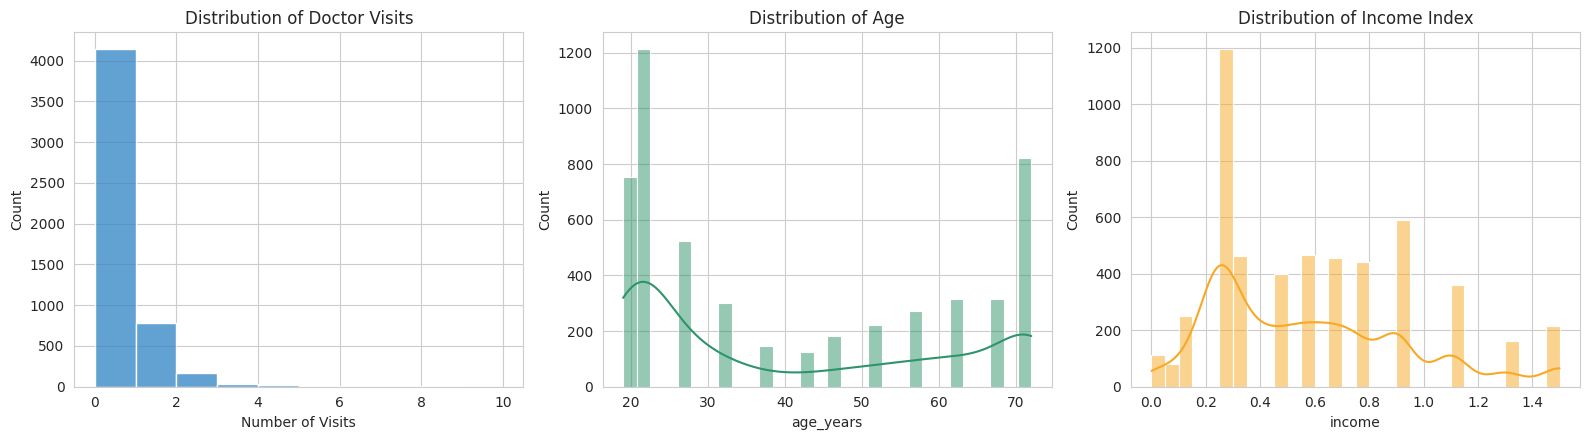

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df['visits'], bins=range(0, 11), ax=axes[0], color='#2E83C3')
axes[0].set_title('Distribution of Doctor Visits')
axes[0].set_xlabel('Number of Visits')

sns.histplot(df['age_years'], bins=30, kde=True, ax=axes[1], color='#2E946B')
axes[1].set_title('Distribution of Age')

sns.histplot(df['income'], bins=30, kde=True, ax=axes[2], color='#F9A825')
axes[2].set_title('Distribution of Income Index')

plt.tight_layout()
plt.savefig('fig0_univariate.png', dpi=150, bbox_inches='tight')
plt.show()

Share of patients with zero visits: 79.8%


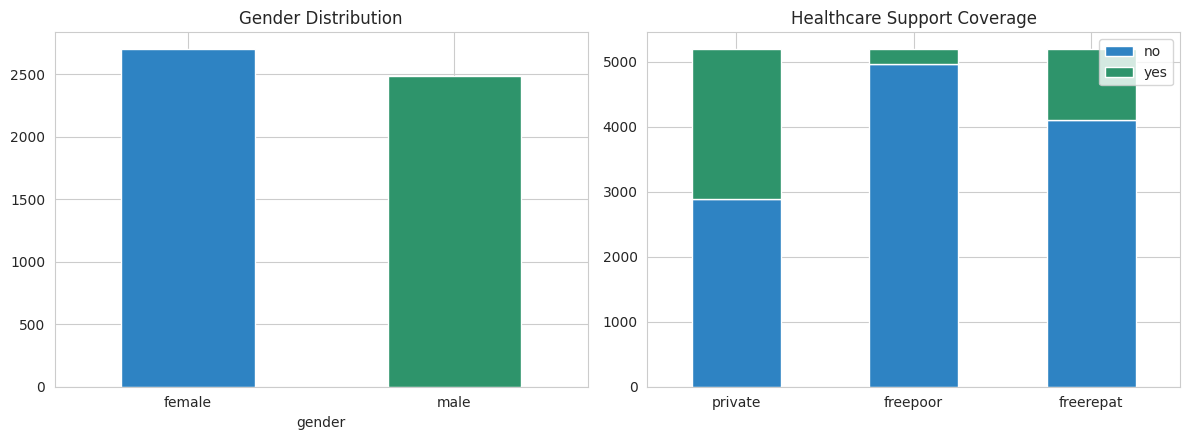

In [11]:
print("Share of patients with zero visits: {:.1f}%".format((df['visits'] == 0).mean() * 100))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df['gender'].value_counts().plot(kind='bar', ax=axes[0], color=['#2E83C3', '#2E946B'])
axes[0].set_title('Gender Distribution')
axes[0].tick_params(axis='x', rotation=0)

support_counts = pd.DataFrame({
    'private': df['private'].value_counts(),
    'freepoor': df['freepoor'].value_counts(),
    'freerepat': df['freerepat'].value_counts(),
}).T
support_counts.plot(kind='bar', stacked=True, ax=axes[1], color=['#2E83C3', '#2E946B'])
axes[1].set_title('Healthcare Support Coverage')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='')

plt.tight_layout()
plt.savefig('fig1_categorical_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** About 80% of patients recorded **zero** doctor visits in the survey period -- and the ~5% of patients with 2+ visits account for roughly half of all visits recorded. Age is bimodal (clusters near 20 and 70) and income skews toward the low end. Private insurance (`private`) is the most common form of coverage (~44%), while `freepoor` (~4%) and `freerepat` (~21%) cover smaller, more targeted groups.

## 7. Bivariate Analysis

Comparing `visits` against each other variable in turn.

### 7.1 Visits vs Demographics and Financial Status

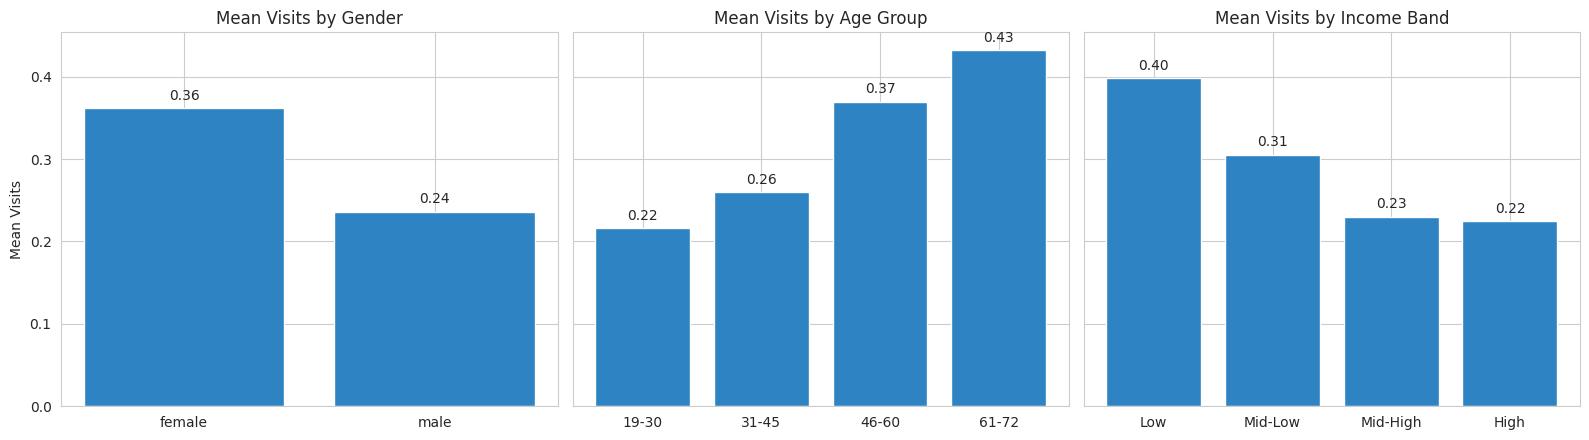

In [12]:
df['age_group'] = pd.cut(df['age_years'], bins=[18, 30, 45, 60, 75], labels=['19-30', '31-45', '46-60', '61-72'])
df['income_band'] = pd.qcut(df['income'], 4, labels=['Low', 'Mid-Low', 'Mid-High', 'High'])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, col, title in zip(axes, ['gender', 'age_group', 'income_band'],
                          ['Mean Visits by Gender', 'Mean Visits by Age Group', 'Mean Visits by Income Band']):
    means = df.groupby(col, observed=True)['visits'].mean()
    ax.bar(means.index.astype(str), means.values, color='#2E83C3')
    for i, v in enumerate(means.values):
        ax.text(i, v + 0.01, f"{v:.2f}", ha='center')
    ax.set_title(title)
axes[0].set_ylabel('Mean Visits')
plt.tight_layout()
plt.savefig('fig2_demographics.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** Women average noticeably more visits than men (0.36 vs 0.24). Visits rise steadily with age (0.22 for ages 19-30 up to 0.43 for 61-72), and -- perhaps surprisingly -- fall as income rises (0.40 in the lowest income band vs 0.22 in the highest). Because income and age are themselves negatively correlated (-0.27), part of the income gradient may reflect age mix rather than income itself.

### 7.2 Visits vs Health Indicators

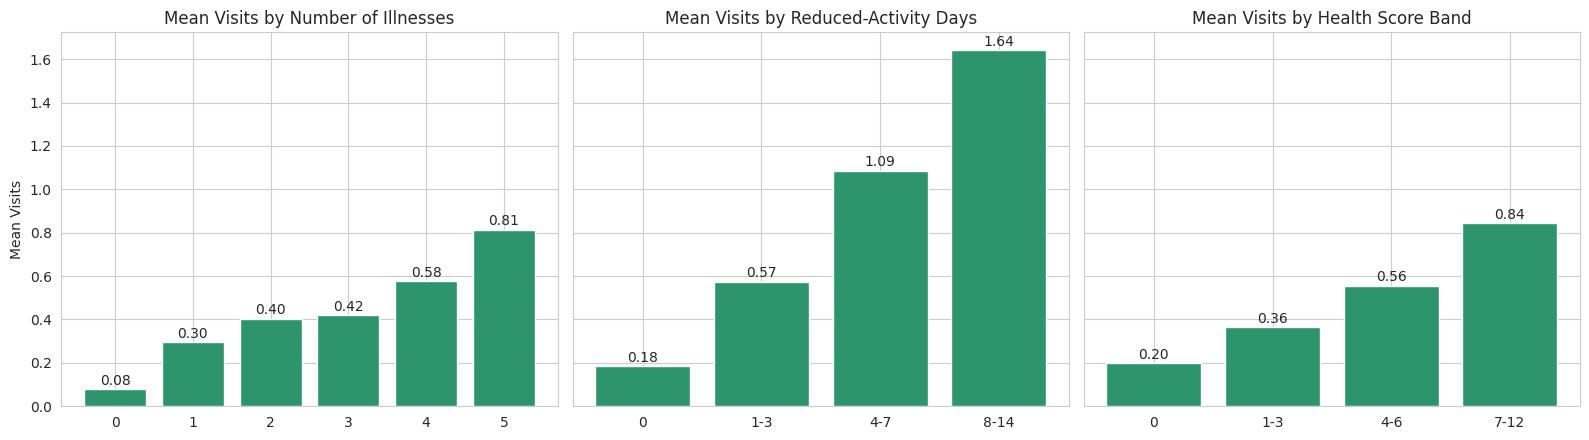

In [13]:
df['reduced_band'] = pd.cut(df['reduced'], bins=[-1, 0, 3, 7, 14], labels=['0', '1-3', '4-7', '8-14'])
df['health_band'] = pd.cut(df['health'], bins=[-1, 0, 3, 6, 12], labels=['0', '1-3', '4-6', '7-12'])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, col, title in zip(axes, ['illness', 'reduced_band', 'health_band'],
                          ['Mean Visits by Number of Illnesses', 'Mean Visits by Reduced-Activity Days',
                           'Mean Visits by Health Score Band']):
    means = df.groupby(col, observed=True)['visits'].mean()
    ax.bar(means.index.astype(str), means.values, color='#2E946B')
    for i, v in enumerate(means.values):
        ax.text(i, v + 0.02, f"{v:.2f}", ha='center')
    ax.set_title(title)
axes[0].set_ylabel('Mean Visits')
plt.tight_layout()
plt.savefig('fig3_health_indicators.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** This is where the clearest signal appears. Mean visits climb steadily with illness count (0.08 with no illnesses to 0.81 with five), with reduced-activity days (0.18 for none to 1.64 for 8-14 days -- the steepest gradient), and with the general-health score (0.20 to 0.84). All three are stronger visible drivers of doctor visits than age, gender, or income.

### 7.3 Visits vs Healthcare Support and Chronic Conditions

             no   yes
private    0.31  0.29
freepoor   0.31  0.16
freerepat  0.26  0.47
nchronic   0.27  0.35
lchronic   0.26  0.60


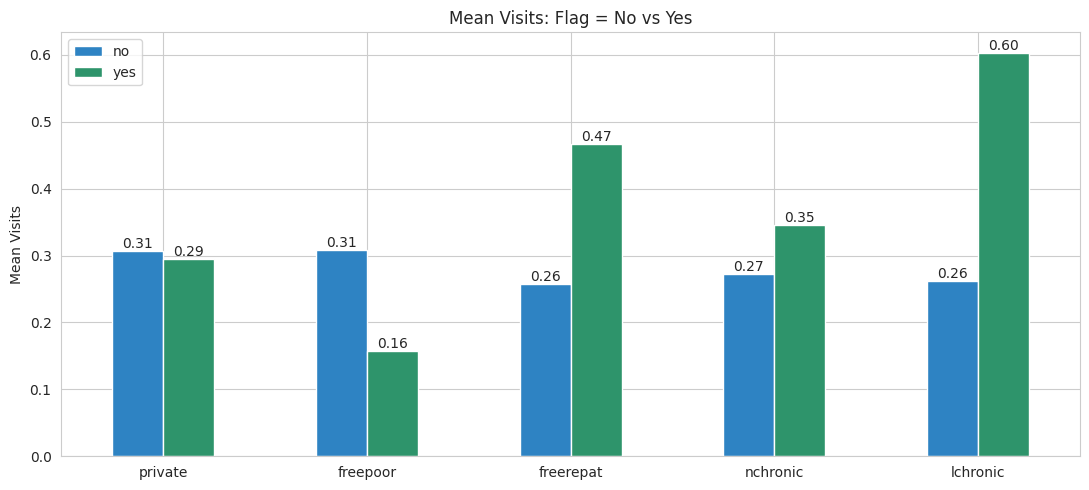

In [14]:
support_cols = ['private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']
rows = {c: df.groupby(c, observed=True)['visits'].mean() for c in support_cols}
support_means = pd.DataFrame(rows).T[['no', 'yes']]
print(support_means.round(2))

ax = support_means.plot(kind='bar', figsize=(11, 5), color=['#2E83C3', '#2E946B'])
ax.set_title('Mean Visits: Flag = No vs Yes')
ax.set_ylabel('Mean Visits')
ax.tick_params(axis='x', rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')
plt.tight_layout()
plt.savefig('fig4_support_chronic.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** Chronic-condition flags and `freerepat` are associated with more visits (`lchronic` 0.60 vs 0.26; `freerepat` 0.47 vs 0.26; `nchronic` 0.35 vs 0.27). Private insurance makes essentially no difference (0.29 vs 0.31). Notably, `freepoor` recipients visit *less* than non-recipients (0.16 vs 0.31) -- the opposite of what a "higher-need" program population might suggest, and explored further in the support-program analysis below.

## 8. Multivariate Analysis

Looking at several variables together: overall correlation structure, and how chronic-condition status interacts with illness count to affect visits.

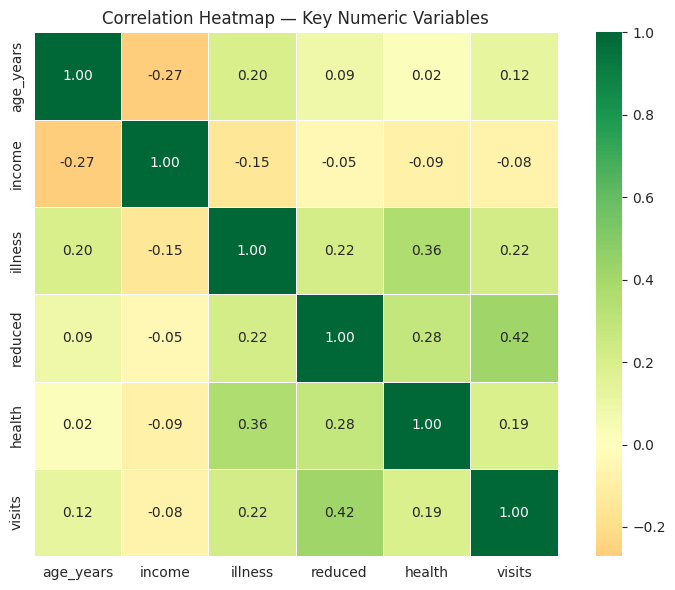

In [15]:
numeric_cols = ['age_years', 'income', 'illness', 'reduced', 'health', 'visits']
plt.figure(figsize=(8, 6))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn', center=0, square=True, linewidths=0.5)
plt.title('Correlation Heatmap — Key Numeric Variables')
plt.tight_layout()
plt.savefig('fig5_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** `reduced` has the strongest relationship with `visits` (0.42), followed by `illness` (0.22) and `health` (0.19); `age_years` is weaker (0.12) and `income` slightly negative (-0.08). These are modest-to-moderate correlations -- visits are a noisy count outcome -- but the ordering confirms the bivariate findings: health indicators matter more than demographics.

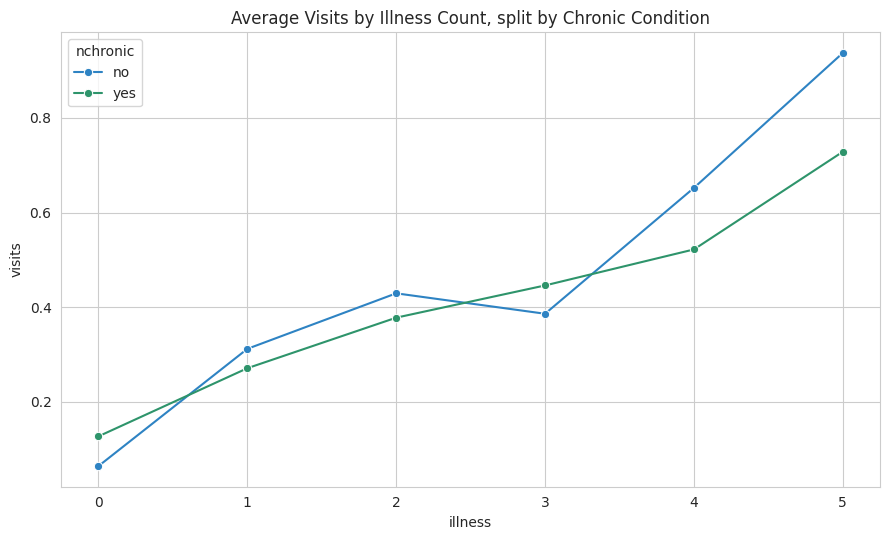

In [16]:
# Does a chronic condition amplify the illness -> visits relationship?
plt.figure(figsize=(9, 5.5))
sns.lineplot(data=df, x='illness', y='visits', hue='nchronic', hue_order=['no', 'yes'],
             palette=['#2E83C3', '#2E946B'], marker='o', errorbar=None)
plt.title('Average Visits by Illness Count, split by Chronic Condition')
plt.tight_layout()
plt.savefig('fig6_illness_chronic_interaction.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** Overall, chronically ill patients average more visits than non-chronic patients (0.35 vs. 0.27). But once illness count is held constant, the two lines largely overlap and even cross -- chronic-condition status does **not** show a consistent independent effect on visits beyond illness count. The simpler explanation holds up better: chronic patients simply report more illnesses on average (1.85 vs. 1.15), and that higher illness count is what drives their higher visit average, not the chronic-condition flag itself.

## 9. Student-Designed Analysis 1: Chronic Conditions & Healthcare Support

*(Independent investigation: do chronic-condition groups differ in how much they use support programs and how often they visit?)*

chronic_group
No chronic condition            2493
Chronic (nchronic)              2092
Long-term chronic (lchronic)     605
Name: count, dtype: int64
                              private  freepoor  freerepat
chronic_group                                             
No chronic condition             44.0       5.7        9.9
Chronic (nchronic)               46.3       2.6       29.1
Long-term chronic (lchronic)     38.2       4.3       39.2


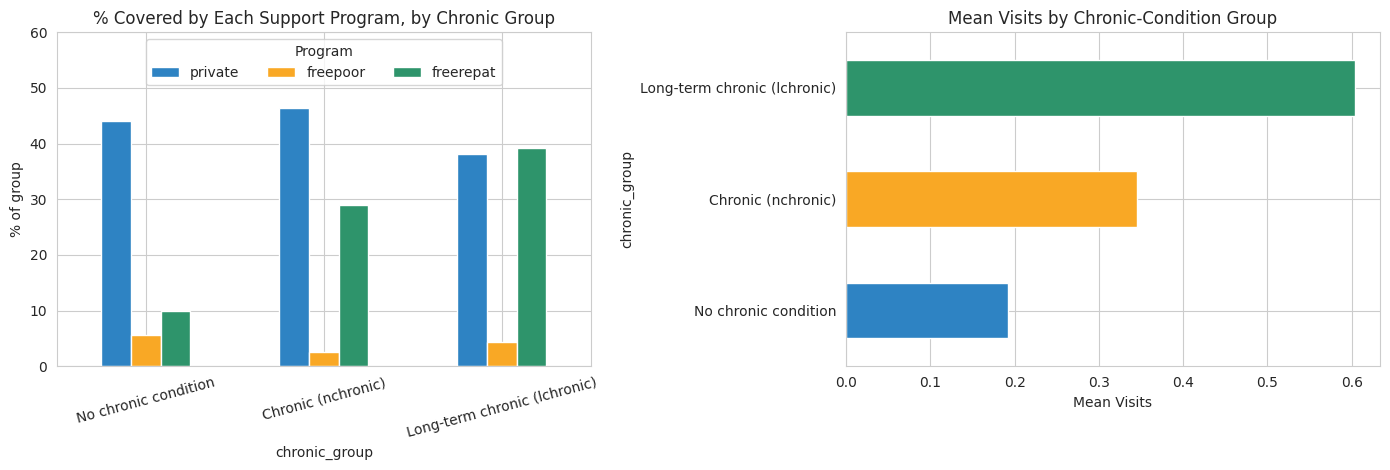

In [17]:
# nchronic and lchronic turn out to be mutually exclusive in this data (no patient is marked
# 'yes' on both), so patients fall into exactly three groups:
df['chronic_group'] = np.select(
    [(df['nchronic'] == 'yes'), (df['lchronic'] == 'yes')],
    ['Chronic (nchronic)', 'Long-term chronic (lchronic)'],
    default='No chronic condition'
)
print(df['chronic_group'].value_counts())

order = ['No chronic condition', 'Chronic (nchronic)', 'Long-term chronic (lchronic)']
coverage = pd.DataFrame({
    c: df.groupby('chronic_group')[c].apply(lambda s: (s == 'yes').mean() * 100) for c in ['private', 'freepoor', 'freerepat']
}).loc[order]
print(coverage.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
coverage.plot(kind='bar', ax=axes[0], color=['#2E83C3', '#F9A825', '#2E946B'])
axes[0].set_title('% Covered by Each Support Program, by Chronic Group')
axes[0].set_ylabel('% of group')
axes[0].tick_params(axis='x', rotation=15)
axes[0].set_ylim(0, 60)
axes[0].legend(title='Program', loc='upper center', ncol=3)

df.groupby('chronic_group')['visits'].mean().loc[order].plot(
    kind='barh', ax=axes[1], color=['#2E83C3', '#F9A825', '#2E946B'])
axes[1].set_title('Mean Visits by Chronic-Condition Group')
axes[1].set_xlabel('Mean Visits')

plt.tight_layout()
plt.savefig('fig7_student1_chronic_support.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** `nchronic` and `lchronic` are **mutually exclusive** in this dataset -- no patient is flagged on both, so every patient falls into exactly one of three groups. The `freerepat` program is far more common among chronic patients (29% of the `nchronic` group and 39% of the `lchronic` group vs 10% of patients with no chronic condition), whereas `freepoor` coverage is similarly low across all three groups (2.6%-5.7%). The **long-term chronic (`lchronic`) group has the highest mean visits (0.60)**, well above the general chronic group (0.35) and those with no chronic condition (0.19).

## 10. Student-Designed Analysis 2: Income & Private Insurance

*(Independent investigation: how does private insurance ownership change with income, and do income or insurance relate to visit counts?)*

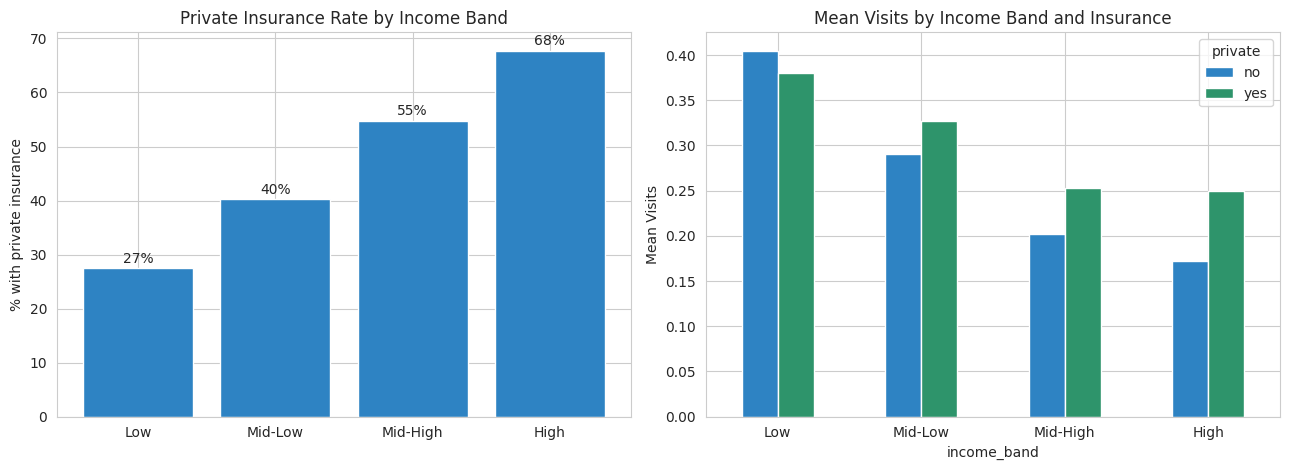

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
priv_rate = df.groupby('income_band', observed=True)['private'].apply(lambda s: (s == 'yes').mean() * 100)
axes[0].bar(priv_rate.index.astype(str), priv_rate.values, color='#2E83C3')
for i, v in enumerate(priv_rate.values):
    axes[0].text(i, v + 1, f"{v:.0f}%", ha='center')
axes[0].set_title('Private Insurance Rate by Income Band')
axes[0].set_ylabel('% with private insurance')

df.groupby(['income_band', 'private'], observed=True)['visits'].mean().unstack().plot(
    kind='bar', ax=axes[1], color=['#2E83C3', '#2E946B'])
axes[1].set_title('Mean Visits by Income Band and Insurance')
axes[1].set_ylabel('Mean Visits')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='private')

plt.tight_layout()
plt.savefig('fig8_student2_income_insurance.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** Private insurance ownership rises sharply with income (27% in the lowest band to 68% in the highest). Mean visits move the other way: lower-income patients visit more on average (0.40 vs 0.22 in the highest band). Holding income band fixed, differences between insured and uninsured patients are small and not consistent in direction (insured patients visit slightly more in the upper bands), so insurance ownership does not explain the income gradient in visits.

## 11. Student-Designed Analysis 3: Health Status vs Visits Across Age Groups

*(Independent investigation: does the relationship between general health score and visits change across age groups?)*

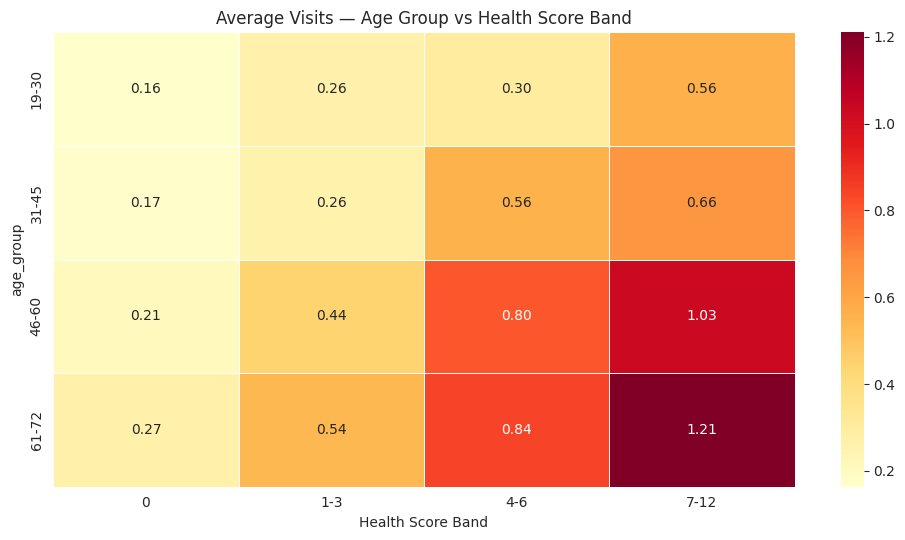

In [19]:
df['age_group'] = pd.cut(df['age_years'], bins=[18, 30, 45, 60, 75],
                          labels=['19-30', '31-45', '46-60', '61-72'])

health_age = df.groupby(['age_group', pd.cut(df['health'], bins=[-1, 0, 3, 6, 12],
                                               labels=['0', '1-3', '4-6', '7-12'])],
                         observed=True)['visits'].mean().unstack()

plt.figure(figsize=(10, 5.5))
sns.heatmap(health_age, annot=True, fmt='.2f', cmap='YlOrRd', linewidths=0.5)
plt.title('Average Visits — Age Group vs Health Score Band')
plt.xlabel('Health Score Band')
plt.tight_layout()
plt.savefig('fig9_student3_health_age.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** Within every age group, average visits climb sharply as the health-score band worsens, and the climb is steepest for the oldest patients (61-72) -- a poor health score appears to translate into more visits most strongly later in life, even though age alone showed little relationship with visits in the bivariate view.

## 12. Key Insights and Findings

1. **Doctor visits are rare and concentrated:** About 80% of patients report zero visits; the ~5% with 2+ visits account for roughly half of all visits recorded.
2. **Health status is the strongest signal:** Mean visits rise from 0.18 (no reduced-activity days) to 1.64 (8-14 days), from 0.08 (no illnesses) to 0.81 (five), and from 0.20 to 0.84 across health-score bands -- far steeper than any demographic gradient.
3. **Chronic status is largely explained by illness count:** Chronically ill (`nchronic`) patients average more visits (0.35 vs 0.27), but once illness count is held constant the gap mostly disappears -- chronic patients simply report more illnesses (1.85 vs 1.15).
4. **The long-term chronic group stands out:** `nchronic` and `lchronic` are mutually exclusive; patients marked `lchronic` have the highest mean visits (0.60), above the general chronic group (0.35) and those with no chronic condition (0.19).
5. **Lower-income patients visit more, but insurance isn't the reason:** Mean visits fall from 0.40 (lowest income band) to 0.22 (highest), while private-insurance rates climb from 27% to 68%. Overall, private and non-private patients visit at nearly identical rates (0.29 vs 0.31), and within income bands the differences are small.
6. **Support programs serve very different populations:** `freerepat` recipients are older (avg. ~65 vs ~34), more often chronically ill (78% have a chronic flag vs 45% of non-recipients) and visit more (0.47 vs 0.26). `freepoor` recipients are much lower-income (mean income index 0.30 vs 0.60) yet visit *less* (0.16 vs 0.31), report fewer illnesses and have fewer chronic flags (37% vs 53%) -- a gap that may point to access barriers, though this data cannot confirm that.
7. **Age and gender matter, and age amplifies poor health:** Women average 0.36 visits vs 0.24 for men; visits rise with age (0.22 to 0.43). Within every age group visits climb as health worsens, most steeply for ages 61-72.
8. **High-visit outliers are consistent, not erroneous:** The 39 patients with 5+ visits report on average 2.6 illnesses, 10.9 reduced-activity days and a health score of 3.4 (vs 1.4, 0.9 and 1.2 overall), and 74% have a chronic-condition flag -- a coherent high-need profile.

## 13. Limitations of the Analysis

- **Cross-sectional survey data:** This is a single-period snapshot, so it can't show whether high-need patients stay high-need over time.
- **Undocumented income units:** The `income` column has no stated currency or scale, so it is treated as a relative index rather than converted to a currency amount.
- **Age/income overlap:** Age and income are negatively correlated (-0.27), so the income gradient in visits may partly reflect age differences; this analysis does not separate the two with a multivariable model.
- **Self-reported health measures:** `illness`, `reduced`, and `health` are survey self-reports, which can vary by respondent even for similar underlying conditions.
- **No causal claims:** All associations are observational (e.g., lower `freepoor` visits could reflect access barriers, better underlying health, or something else entirely).
- **Small high-visit subgroup:** Only 39 patients have 5+ visits, so conclusions about the most extreme visitors rest on few records.

## 14. Conclusions and Recommendations

### Final Conclusion
Doctor visits in this dataset are concentrated in a small group of high-need patients, and the best predictors of visits are **health-status measures** -- reduced-activity days, illness count, and general-health score -- rather than demographics or insurance. Long-term chronic patients and `freerepat` recipients (older, sicker) visit most, while lower-income patients visit more than higher-income ones and `freepoor` recipients visit notably less. Private insurance ownership tracks income but shows no relationship with visit frequency.

**Recommendations for evidence-based healthcare planning:**
- Prioritize **outreach and monitoring for long-term chronic (`lchronic`) patients** and for patients with many reduced-activity days, since they show the highest visit burden.
- Focus **preventive care on older patients with declining health scores**, where the health-to-visits relationship is steepest.
- **Review access for `freepoor` recipients**: they are lower-income and visit less despite similar-or-lower illness counts than average; a follow-up should check whether cost or access barriers play a role.
- Recognize that **expanding private insurance alone is unlikely to change visit frequency**, based on the similar visit levels between insured and uninsured patients here.
- Investigate the **small high-visit subgroup directly** (e.g., case review), since ~5% of patients drive about half of all visits.

**Scope for further work:** Extend with longitudinal data to see whether high-need patients stay high-need, and fit a count-data regression (Poisson or negative binomial) to estimate each factor's effect while controlling for the others -- in particular to separate the age, income and gender effects noted above.